In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Delivery_Logistics_Cleaned.csv")
df.head(5)

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,8,no,delivered,3,1632.7206
1,250,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,3,no,delivered,5,640.1700
2,250,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,16,no,delivered,4,1448.1700
3,250,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,8,no,delivered,3,1486.5700
4,250,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,16,no,delivered,4,1394.5600


In [3]:
Categorical_cols = [col for col in df.columns if df[col].dtype == 'object']
Categorical_cols

['delivery_partner',
 'package_type',
 'vehicle_type',
 'delivery_mode',
 'region',
 'weather_condition',
 'delayed',
 'delivery_status']

In [4]:
Numerical_cols = [col for col in df.columns if df[col].dtype != 'object']
Numerical_cols

['delivery_id',
 'distance_km',
 'package_weight_kg',
 'delivery_time_hours',
 'expected_time_hours',
 'delivery_rating',
 'delivery_cost']

In [5]:
#Top 10 Delivery ID's.

df["delivery_id"].value_counts().head(10)

delivery_id
24750    251
250      250
270        1
24735      1
24734      1
255        1
253        1
24720      1
24721      1
24722      1
Name: count, dtype: int64

### As we can see only 2 delivery ID's have multiple rows under it.

In [6]:
# Overview of Distannce in kilometers
df["distance_km"].describe()

count    25000.000000
mean       150.390436
std         86.409745
min          3.600000
25%         75.900000
50%        151.000000
75%        224.900000
max        297.100000
Name: distance_km, dtype: float64

## On an average every delivery partner travels 150 kms for a single delivery.
## The highest distance and lowest distance travelled for a single delivery is 297 kms and 3.6 kms.


In [7]:
df.groupby(["delivery_partner"]).agg({"distance_km": ["sum","mean", "min", "max"]}).sort_values(by=("distance_km", "sum"), ascending=False)

distance_km                        
                         sum        mean  min    max
delivery_partner                                    
xpressbees          426653.9  150.974487  3.6  297.1
dhl                 426140.5  152.084404  3.6  297.1
ekart               424537.7  151.566476  3.6  297.1
fedex               419258.4  148.778708  3.6  297.1
blue dart           418968.9  149.738706  3.6  297.1
shadowfax           413239.3  151.037756  3.6  297.1
ecom express        411202.2  151.066201  3.6  297.1
amazon logistics    410112.4  151.277167  3.6  297.1
delhivery           409647.6  147.037904  3.6  297.1

## Delivery Partner named Xpressbees has the highest distance travelled which is of 4,26,654 kms.
## Delivery partner named delhivery has the lowest distance covered which is of 4,09,647.6 kms.

## DHL has the highest Average of distance travelled and delhivery has the lowest average of distance travelled.

## Every delivery partner has two things in common one is 'minimum distance travelled'(3.6) and another one is 'maximum disatance travelled'(297.1).


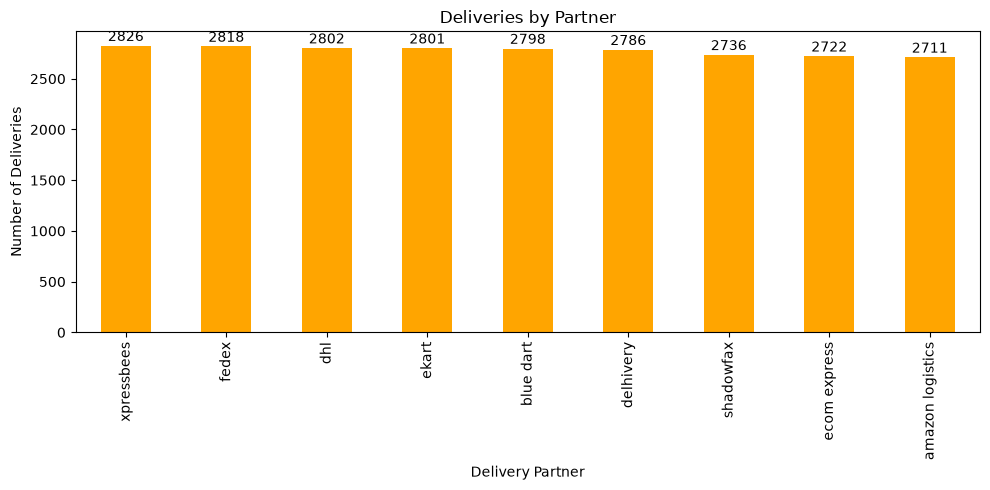

In [8]:
ax = df["delivery_partner"].value_counts().plot(
    kind="bar", figsize=(10, 5), color="orange"
)
ax.bar_label(ax.containers[0], fmt="%d", padding=1)
ax.set_title("Deliveries by Partner")
ax.set_xlabel("Delivery Partner")
ax.set_ylabel("Number of Deliveries")
plt.tight_layout()

In [9]:
df

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,8,no,delivered,3,1632.7206
1,250,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,3,no,delivered,5,640.1700
2,250,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,16,no,delivered,4,1448.1700
3,250,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,8,no,delivered,3,1486.5700
4,250,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,16,no,delivered,4,1394.5600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,24750,dhl,furniture,scooter,two day,east,foggy,80.7,3.65,4,16,no,delivered,5,414.4500
24996,24750,ecom express,automobile parts,ev van,standard,west,clear,172.9,21.42,5,24,no,delivered,5,928.7600
24997,24750,ekart,clothing,scooter,same day,east,rainy,168.4,4.85,9,8,yes,delayed,2,956.5500
24998,24750,shadowfax,documents,ev van,standard,west,stormy,37.2,8.04,6,24,no,delivered,5,210.1200


In [15]:
df.groupby(["delivery_status","delayed"]).agg({"delivery_id": "count"}).sort_values(by=("delivery_id"), ascending=False)

,,delivery_id
delivery_status,delayed,
delivered,no,18331
delayed,yes,5341
failed,yes,1328


# There are 18331 instances when a product has been delivered and the delivery was not delayed.
# Likewise there 5341 instances where the delivery was sucessfull but there was some time delay.
# there are total of 1328 deliveries which are both failed and also delayed. Which means these are unsucessfull ones.

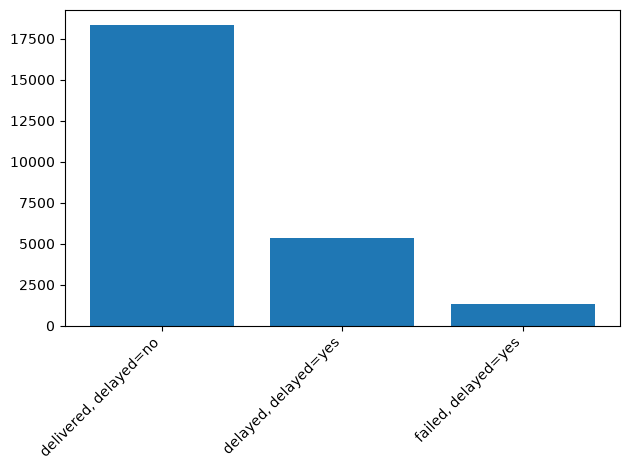

In [16]:
counts = (
    df.groupby(["delivery_status", "delayed"])["delivery_id"]
      .count()
      .sort_values(ascending=False)
)

labels = [f"{status}, delayed={delayed}" for status, delayed in counts.index]

plt.bar(labels, counts.to_numpy())
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [17]:
Categorical_cols

['delivery_partner',
 'package_type',
 'vehicle_type',
 'delivery_mode',
 'region',
 'weather_condition',
 'delayed',
 'delivery_status']

In [18]:
#Failed Delivery rates per each region
failed_delivery_rates = df[df['delivery_status'] == 'failed'].groupby('region')["delivery_id"].count() / df.groupby('region')["delivery_id"].count()

In [19]:
print(failed_delivery_rates * 100)

region
central    5.652174
east       4.980687
north      4.768640
south      5.505324
west       5.632974
Name: delivery_id, dtype: float64


# The Central, West and the south regions have the delivery fail rate for their respective overall delivery above 5 percent.
# The east and the north regions have delivery fail rate for their respective overall delivery below 5 percent.

In [21]:
df[ 'delivery_status'].value_counts(normalize=True) * 100

delivery_status
delivered    73.324
delayed      21.364
failed        5.312
Name: proportion, dtype: float64

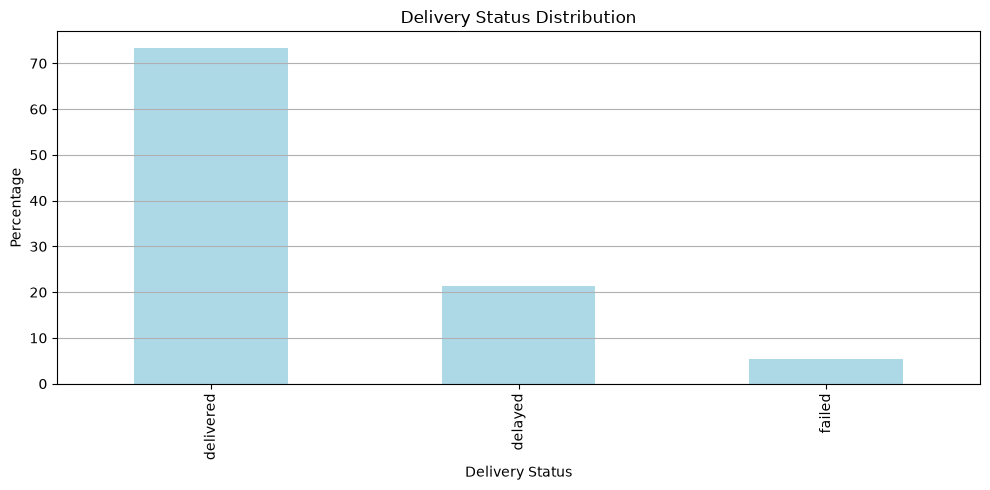

In [22]:
delivery_status = df[ 'delivery_status'].value_counts(normalize=True) * 100
delivery_status.plot(kind='bar', figsize=(10, 5), color='lightblue')
plt.title('Delivery Status Distribution')
plt.xlabel('Delivery Status')
plt.ylabel('Percentage')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Over 73.32 Percentage of total deliveries are marked sucessfull and 21.36 percentage of total deliveries and being marked delayed and also successfull. So the total rate of sucessfull deliveries over total deliveries is around 94 percentage.

# Over 5.3 percentage of total deliveries have been marked as failed deliveries.

In [24]:
#delivery fail percentage by each region and weather condition over total deliveries.
failed_delivery_rates = df[df['delivery_status'] == 'failed'].groupby(['region', 'weather_condition']).size() / df.groupby(['region', 'weather_condition']).size() * 100
failed_delivery_rates

region   weather_condition
central  clear                 3.407756
         cold                  2.686203
         foggy                 6.944444
         hot                   2.500000
         rainy                 7.558140
         stormy               10.392610
east     clear                 2.586207
         cold                  3.352601
         foggy                 5.707196
         hot                   2.481390
         rainy                 7.169811
         stormy                8.622754
north    clear                 3.221809
         cold                  3.268765
         foggy                 4.869359
         hot                   3.337612
         rainy                 6.628571
         stormy                7.073171
south    clear                 2.808303
         cold                  2.644231
         foggy                 6.447831
         hot                   3.810624
         rainy                 8.953342
         stormy                8.599509
west     clea

Intermediate Data Matrix (Failure %):
weather_condition  clear  cold  foggy   hot  rainy  stormy
region                                                    
central             3.41  2.69   6.94  2.50   7.56   10.39
east                2.59  3.35   5.71  2.48   7.17    8.62
north               3.22  3.27   4.87  3.34   6.63    7.07
south               2.81  2.64   6.45  3.81   8.95    8.60
west                3.83  3.80   5.62  3.98   6.72    9.73


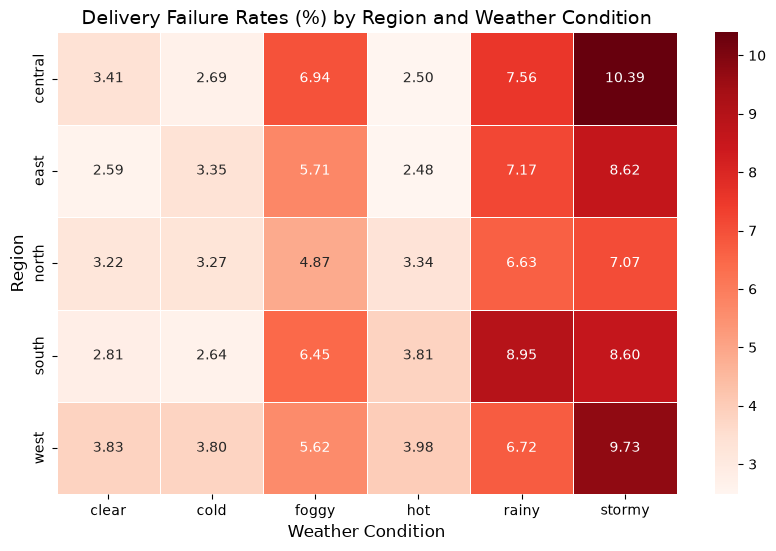

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data
df = pd.read_csv('Delivery_Logistics_Cleaned.csv')

# 2. Calculate failure rates as percentages
failed_delivery_rates = (df[df['delivery_status'] == 'failed'].groupby(['region', 'weather_condition']).size() / 
                         df.groupby(['region', 'weather_condition']).size()) * 100

# 3. INTERMEDIATE STEP: Unstack the data to create a matrix (Rows = Region, Columns = Weather)
failure_matrix = failed_delivery_rates.unstack()
print("Intermediate Data Matrix (Failure %):")
print(failure_matrix.round(2))

# 4. Generate the Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(failure_matrix, annot=True, fmt=".2f", cmap="Reds", linewidths=0.5)

# Add titles and labels
plt.title('Delivery Failure Rates (%) by Region and Weather Condition', fontsize=14)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('Region', fontsize=12)
plt.show()


# The overall delivery failure rate across the entire network is 5.3%, but combining weather and geography reveals exactly where the system breaks down. Stormy and rainy conditions are the primary drivers of failed deliveries, heavily impacting specific regions.

**The Stormy Bottleneck:** The Central region struggles the most during stormy weather, hitting a network-high failure rate of 10.39%. The West region is similarly impacted, failing at a 9.73% rate during storms.

 **High Reliability Zones:** Deliveries run very smoothly during hot and clear weather. The East region during hot weather experiences the lowest failure rate in the entire dataset at just 2.48%.
 
**Baseline Regional Performance:** Even without factoring in weather, the Central (5.65%) and West (5.63%) regions have the highest overall failure rates. The North region is the most reliable overall, with a failure rate of just 4.77%.



In [27]:
#Analysing which vehilce type and weather condition has the highest delivery failure rate.
df[["vehicle_type", "weather_condition", "delivery_status"]].groupby(["vehicle_type", "weather_condition"]).apply(lambda x: (x["delivery_status"] == "failed").sum() / len(x) * 100).reset_index(name="failure_rate").sort_values(by="failure_rate", ascending=False)

,vehicle_type,weather_condition,failure_rate
29,truck,stormy,10.071942
11,ev bike,stormy,9.425626
35,van,stormy,9.014085
5,bike,stormy,8.477011
23,scooter,stormy,8.253095
17,ev van,stormy,8.248915
10,ev bike,rainy,7.832168
26,truck,foggy,7.782673
4,bike,rainy,7.759883
34,van,rainy,7.660167


In [30]:
# finding the delivery delay percentage by each vehicle type and weather condition over total deliveries.
delay_rates = df[df['delayed'] == 'yes'].groupby(['vehicle_type', 'weather_condition']).size() / df.groupby(['vehicle_type', 'weather_condition']).size() * 100
delay_rates

vehicle_type  weather_condition
bike          clear                16.061453
              cold                 18.361153
              foggy                31.170663
              hot                  17.360115
              rainy                39.092240
              stormy               40.229885
ev bike       clear                19.054878
              cold                 14.772727
              foggy                29.972376
              hot                  15.270270
              rainy                38.881119
              stormy               40.942563
ev van        clear                17.790531
              cold                 15.549215
              foggy                30.027933
              hot                  19.478528
              rainy                35.811836
              stormy               41.244573
scooter       clear                14.940828
              cold                 15.317919
              foggy                28.675400
              hot      

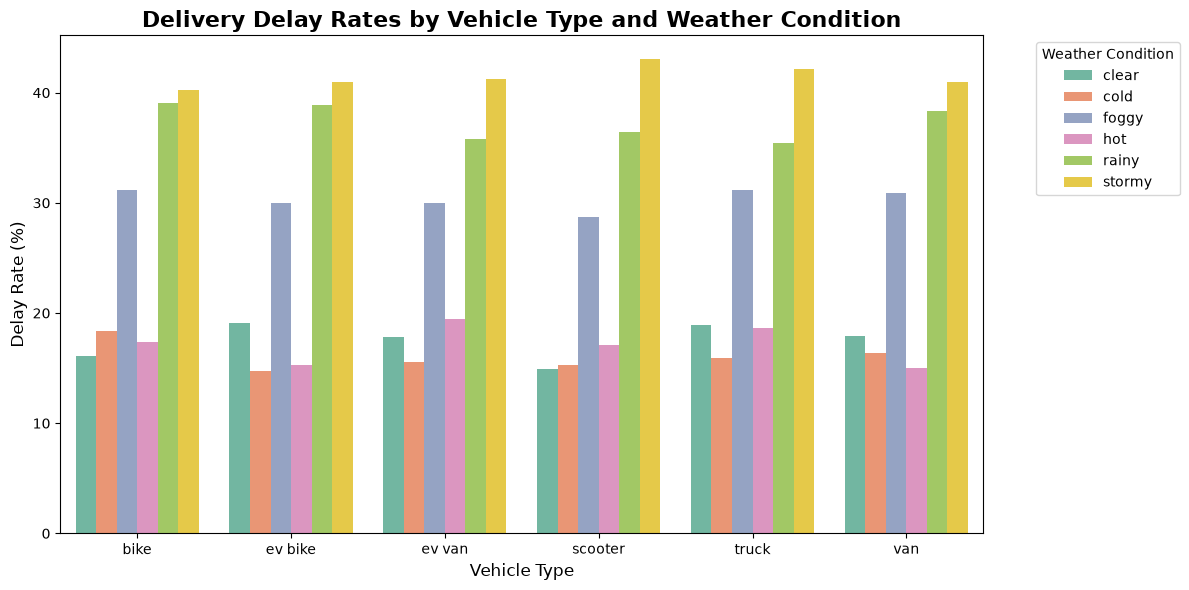

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('Delivery_Logistics_Cleaned.csv')

# 2. Calculate the delay rates
delay_rates = (df[df['delayed'] == 'yes'].groupby(['vehicle_type', 'weather_condition']).size() / 
               df.groupby(['vehicle_type', 'weather_condition']).size()) * 100

# 3. INTERMEDIATE STEP: Convert the Series to a DataFrame so Seaborn can read it easily
delay_df = delay_rates.reset_index(name='delay_percentage')

# 4. Create the grouped bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    data=delay_df, 
    x='vehicle_type', 
    y='delay_percentage', 
    hue='weather_condition',
    palette='Set2'  # A nice distinct color palette
)

# 5. Formatting the chart for readability
plt.title('Delivery Delay Rates by Vehicle Type and Weather Condition', fontsize=16, fontweight='bold')
plt.xlabel('Vehicle Type', fontsize=12)
plt.ylabel('Delay Rate (%)', fontsize=12)
plt.legend(title='Weather Condition', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Observation**: 

The Storm Bottleneck for Two-Wheelers
The grouped bar chart clearly shows that stormy weather completely disrupts the network, pushing delay rates past 40% across almost every vehicle type. The most severe bottleneck happens with scooters, which face a massive 43.05% delay rate during storms. Standard trucks also struggle heavily, hitting 42.15%.

**Broader Business Implication & Strategy**
Because nearly half of all scooter deliveries will be late during a storm, the business needs to stop relying on static delivery rules. When the weather forecast predicts severe storms, the logistics system should automatically pause scooter and bike assignments. Instead, packages should be routed to enclosed vehicles like EV vans.

# More importantly, the company can use this exact 43% failure rate to adjust customer expectations. During stormy weather, the website should automatically add a 24-hour buffer to the estimated delivery time at checkout. By fixing the expectation before the customer even pays, the business protects its customer satisfaction score and prevents angry support calls.

In [32]:
Categorical_cols

['delivery_partner',
 'package_type',
 'vehicle_type',
 'delivery_mode',
 'region',
 'weather_condition',
 'delayed',
 'delivery_status']

In [33]:
#Failure rate for each weather condition.
df[df['delivery_status'] == 'failed'].groupby('weather_condition')["delivery_id"].count() / df.groupby('weather_condition')["delivery_id"].count() * 100

weather_condition
clear     3.176528
cold      3.150553
foggy     5.925575
hot       3.244552
rainy     7.384320
stormy    8.909004
Name: delivery_id, dtype: float64

In [34]:
Failure_rates_for_weather_condition = df[df['delivery_status'] == 'failed'].groupby('weather_condition')["delivery_id"].count() / df.groupby('weather_condition')["delivery_id"].count() * 100

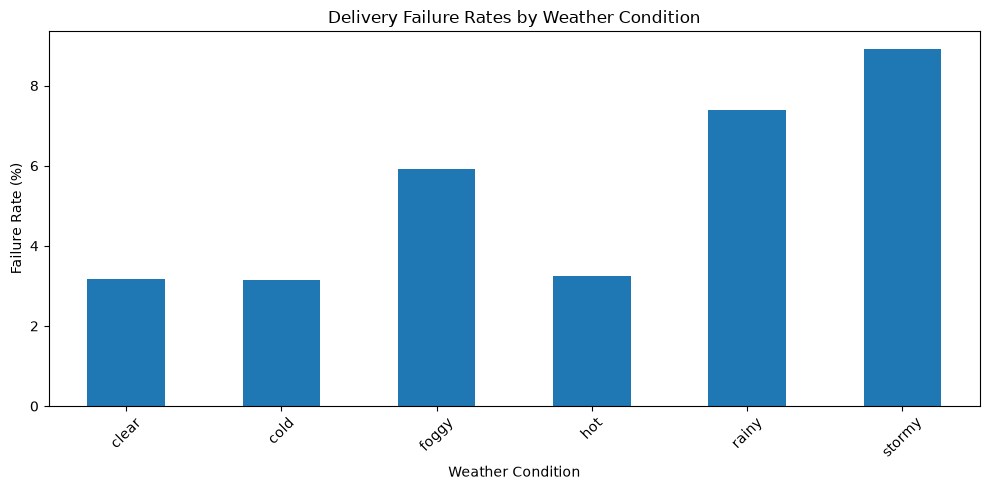

In [40]:
#Visualising the samething using a bar chart.
plt.figure(figsize=(10,5))
Failure_rates_for_weather_condition.plot(kind='bar')
plt.xlabel('Weather Condition')
plt.ylabel('Failure Rate (%)')
plt.title('Delivery Failure Rates by Weather Condition')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## ANALYSING THE NUMERICAL COLUMNS

In [45]:
Numerical_cols

['delivery_id',
 'distance_km',
 'package_weight_kg',
 'delivery_time_hours',
 'expected_time_hours',
 'delivery_rating',
 'delivery_cost']

In [46]:
df.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,8,no,delivered,3,1632.7206
1,250,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,3,no,delivered,5,640.1700
2,250,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,16,no,delivered,4,1448.1700
3,250,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,8,no,delivered,3,1486.5700
4,250,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,16,no,delivered,4,1394.5600


In [49]:
df_num_wanted = df.drop(columns=['delivery_id', 'region', 'delivery_partner', 'vehicle_type', 'weather_condition', 'delivery_status', 'delayed','package_type','delivery_mode'])

In [50]:
df_num_wanted.head()

,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delivery_rating,delivery_cost
0,297.0,46.96,8,8,3,1632.7206
1,89.6,47.39,2,3,5,640.1700
2,273.5,26.89,10,16,4,1448.1700
3,269.7,12.69,6,8,3,1486.5700
4,256.7,37.02,9,16,4,1394.5600


In [52]:
Numerical_correlations = df_num_wanted.corr()

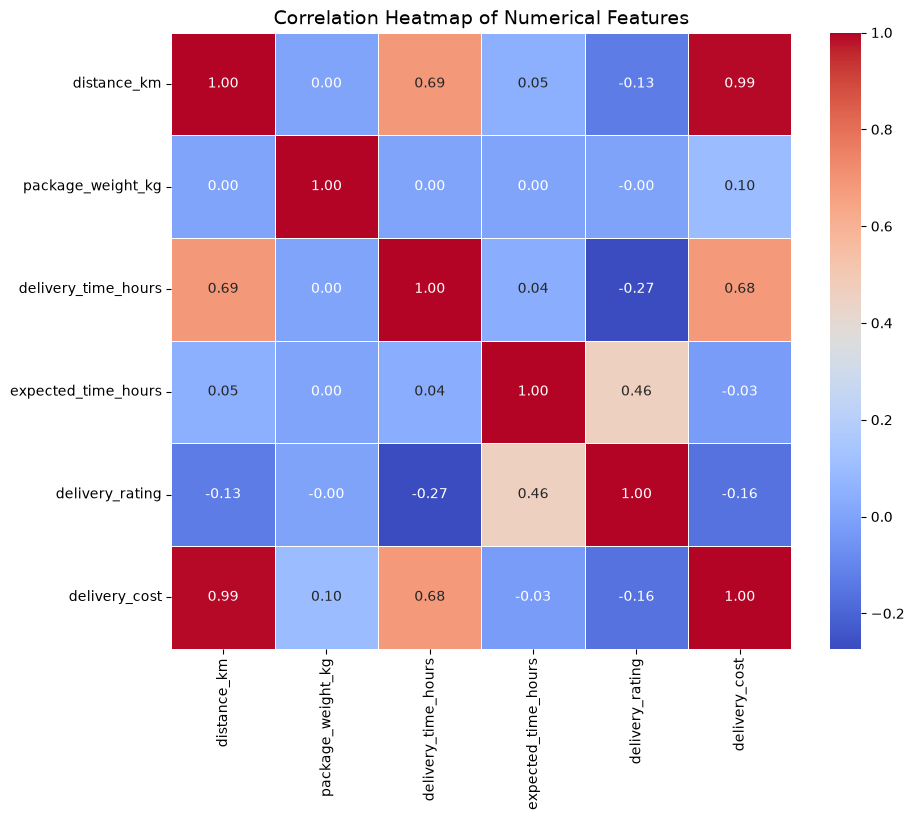

In [53]:
plt.figure(figsize=(10, 8))
sns.heatmap(Numerical_correlations, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14)
plt.show()

**Observation 1: Distance is the Only Cost Driver**
The heatmap shows an almost perfect positive correlation (0.99) between `distance_km` and `delivery_cost`. This reveals that the logistics network's pricing model is driven entirely by how far a package travels, while completely ignoring `package_weight_kg` (which has a near-zero 0.10 correlation with cost).

**Observation 2: The Expectation Game**
Actual delivery time hurts customer satisfaction, shown by the negative correlation (-0.27) between `delivery_time_hours` and `delivery_rating`. However, there is a strong positive correlation (0.46) between `expected_time_hours` and `delivery_rating`. Customers rate the delivery higher when they are given a longer expected delivery window upfront.

**Broader Business Implication & Strategy**
The company is likely losing money on heavy, short-distance shipments because weight is not currently factored into the cost. The business must update its pricing model to charge a premium for heavier packages.

Furthermore, to immediately boost customer satisfaction scores, the business should practice "under-promising and over-delivering." Because longer expected times correlate with higher ratings, adding a deliberate 12-to-24 hour buffer to the expected delivery time shown to the customer at checkout will successfully manage their expectations and result in better feedback.

In [54]:
df_num_wanted.describe()

,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delivery_rating,delivery_cost
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,150.390436,25.145898,6.248040,13.107680,3.666000,864.944579
std,86.409745,14.368663,3.140935,7.559024,1.149964,435.712593
min,3.600000,0.670000,0.000000,2.000000,1.000000,95.667400
25%,75.900000,12.680000,4.000000,8.000000,3.000000,490.800000
50%,151.000000,25.145000,6.000000,8.000000,4.000000,867.535000
75%,224.900000,37.660000,8.000000,16.000000,5.000000,1237.910000
max,297.100000,49.520000,19.000000,24.000000,5.000000,1632.720600


**Observation 1: The "Under-Promise, Over-Deliver" Buffer**
The summary statistics reveal a massive built-in buffer between when a package actually arrives and when it is promised to the customer. The average actual delivery time is only 6.25 hours, but the average expected time quoted to the customer is more than double that at 13.11 hours. Even looking at the 75th percentile, shipments are physically delivered in 8 hours, while the promised window is set to 16 hours.

**Observation 2: A Potential Data Logging Anomaly**
The minimum value for `delivery_time_hours` is exactly 0.00 hours. Since physical delivery takes time, this suggests a data entry error, a system glitch, or perhaps an immediate in-store pickup being improperly categorized alongside standard logistics dispatches.

**Broader Business Implication & Strategy**
The company is heavily padding its delivery estimates by an average of nearly 7 hours. While this strategy successfully protects the customer satisfaction score (resulting in a strong median rating of 4.0 out of 5), it could be costing the business sales. Customers shopping online often abandon carts if delivery estimates are too long. Because the logistics network is routinely completing 75% of all deliveries in 8 hours or less, the business could safely tighten its advertised shipping times at checkout to win more sales without changing anything about its physical operations. Furthermore, the 0.00 delivery time records should be investigated and filtered out to prevent them from artificially lowering the average delivery time metric.

## NUMERICAL AND CATEGORICAL ANALYSIS

In [55]:
df.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,8,no,delivered,3,1632.7206
1,250,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,3,no,delivered,5,640.1700
2,250,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,16,no,delivered,4,1448.1700
3,250,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,8,no,delivered,3,1486.5700
4,250,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,16,no,delivered,4,1394.5600


In [60]:
#Analysing the vehicle_type and distance_km.
df.groupby('vehicle_type')['distance_km'].agg(['mean', 'median', 'min', 'max','sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
vehicle_type,,,,,
bike,151.423462,152.50,3.6,297.1,629921.6
ev bike,151.044500,152.45,3.6,297.1,637105.7
ev van,150.679057,152.00,3.6,297.1,620195.0
truck,150.265549,150.10,3.6,297.1,622850.7
scooter,150.160541,150.70,3.6,297.1,626770.1
van,148.774254,145.80,3.6,297.1,622917.8


As We can see there is no such differences between the vehilce types and their performances in terms of distance travelled by each of them.

In [59]:
#Vehilce type vs Ratings.
df.groupby('vehicle_type')['delivery_rating'].agg(['mean', 'median', 'min', 'max','std']).sort_values(by='mean', ascending=False)

,mean,median,min,max,std
vehicle_type,,,,,
ev van,3.678086,4.0,1,5,1.149194
scooter,3.677048,4.0,1,5,1.138047
ev bike,3.667852,4.0,1,5,1.146766
truck,3.666104,4.0,1,5,1.165367
van,3.660855,4.0,1,5,1.149005
bike,3.646154,4.0,1,5,1.151761


In [62]:
df.groupby('vehicle_type')['package_weight_kg'].agg(['mean', 'median', 'min', 'max','sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
vehicle_type,,,,,
ev bike,25.427750,25.785,0.67,49.52,107254.25
truck,25.414770,25.690,0.67,49.52,105344.22
van,25.368094,25.520,0.67,49.52,106216.21
ev van,25.018737,24.585,0.67,49.52,102977.12
bike,25.008192,24.930,0.67,49.52,104034.08
scooter,24.633819,24.315,0.67,49.52,102821.56


In [63]:
df.groupby('vehicle_type')['delivery_cost'].agg(['mean', 'median', 'min', 'max','sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
vehicle_type,,,,,
ev bike,869.235484,882.595,95.6674,1632.7206,3.666435e+06
bike,868.917038,878.670,95.6674,1632.7206,3.614695e+06
ev van,866.181463,871.795,95.6674,1632.7206,3.565203e+06
truck,864.768182,858.580,95.6674,1632.7206,3.584464e+06
scooter,862.914003,869.070,95.6674,1632.7206,3.601803e+06
van,857.658050,845.190,95.6674,1632.7206,3.591014e+06


In [65]:
df.groupby('delivery_mode')['distance_km'].agg(['mean', 'median', 'min', 'max','sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
delivery_mode,,,,,
same day,151.161236,152.5,3.6,297.1,949141.4
express,150.954805,151.7,3.6,297.1,940901.3
two day,150.811203,151.8,3.6,297.1,950412.2
standard,148.610734,147.0,3.6,297.1,919306.0


In [68]:
df.groupby('region')['delivery_cost'].agg(['mean', 'median', 'min', 'max', 'sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
region,,,,,
west,874.211232,881.78,95.6674,1632.7206,4.454106e+06
central,869.950989,869.74,95.6674,1632.7206,4.401952e+06
east,861.455929,873.47,95.6674,1632.7206,4.237502e+06
north,860.439223,867.79,95.6674,1632.7206,4.258314e+06
south,858.296324,846.26,95.6674,1632.7206,4.271741e+06


In [70]:
df.groupby('weather_condition')['delivery_time_hours'].agg(['mean', 'median', 'min', 'max', 'sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
weather_condition,,,,,
stormy,8.807527,9.0,2,19,36974
rainy,7.804843,8.0,1,17,32554
foggy,6.486608,6.0,0,17,27367
hot,4.784504,5.0,0,14,19760
clear,4.776431,5.0,0,14,19698
cold,4.773449,5.0,0,13,19848


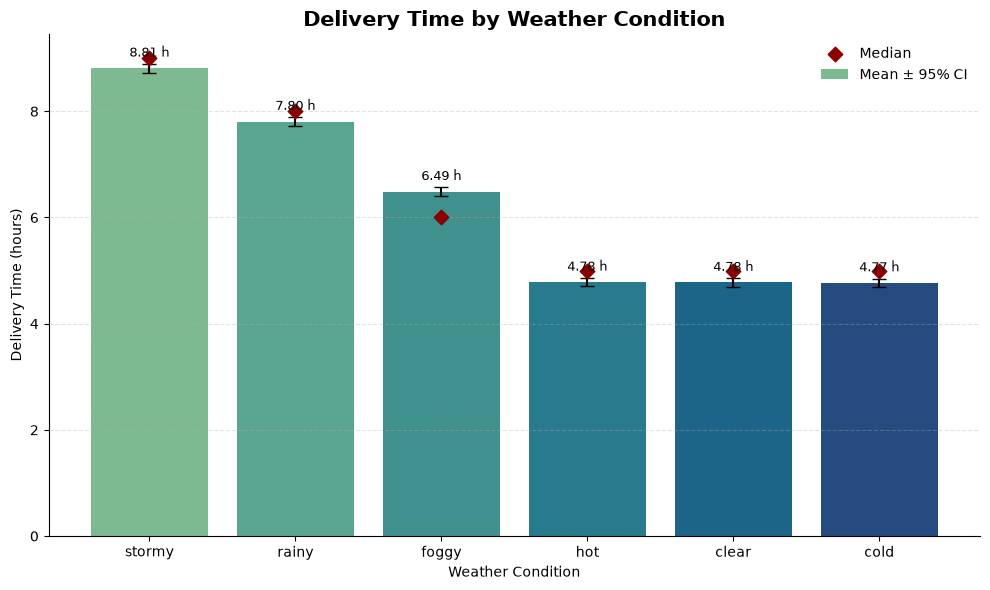

In [71]:
weather_time = (
    df.groupby("weather_condition")["delivery_time_hours"]
      .agg(mean="mean", median="median", std="std", count="count")
      .sort_values("mean", ascending=False)
)

weather_time["ci95"] = 1.96 * weather_time["std"] / np.sqrt(weather_time["count"])

fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("crest", n_colors=len(weather_time))
x = np.arange(len(weather_time))

bars = ax.bar(
    x,
    weather_time["mean"],
    color=colors,
    yerr=weather_time["ci95"],
    capsize=5,
    error_kw={"elinewidth": 1.5},
    label="Mean ± 95% CI"
)

ax.scatter(
    x,
    weather_time["median"],
    color="darkred",
    marker="D",
    s=55,
    zorder=3,
    label="Median"
)

for bar, row in zip(bars, weather_time.itertuples()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + row.ci95 + 0.08,
        f"{row.mean:.2f} h",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(weather_time.index)
ax.set_title("Delivery Time by Weather Condition", fontsize=15, weight="bold")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Delivery Time (hours)")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [72]:
df.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,8,no,delivered,3,1632.7206
1,250,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,3,no,delivered,5,640.1700
2,250,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,16,no,delivered,4,1448.1700
3,250,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,8,no,delivered,3,1486.5700
4,250,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,16,no,delivered,4,1394.5600


In [73]:
df['package_type'].value_counts()

package_type
fragile items       2848
pharmacy            2810
documents           2805
automobile parts    2795
electronics         2792
clothing            2767
furniture           2746
cosmetics           2744
groceries           2693
Name: count, dtype: int64

In [74]:
df.groupby('package_type')['delivery_cost'].agg(['mean', 'median', 'min', 'max','sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
package_type,,,,,
clothing,879.421551,892.400,95.6674,1632.7206,2.433359e+06
automobile parts,877.182380,881.120,95.6674,1632.7206,2.451725e+06
pharmacy,873.003255,888.295,95.6674,1632.7206,2.453139e+06
cosmetics,870.800874,869.710,95.6674,1632.7206,2.389478e+06
furniture,866.719703,876.810,95.6674,1632.7206,2.380012e+06
groceries,861.846692,851.450,95.6674,1632.7206,2.320953e+06
electronics,857.739423,850.405,95.6674,1632.7206,2.394808e+06
documents,850.833296,834.910,95.6674,1632.7206,2.386587e+06
fragile items,847.455137,842.155,95.6674,1632.7206,2.413552e+06


In [75]:
df.groupby('package_type')['package_weight_kg'].agg(['mean', 'median', 'min', 'max','sum']).sort_values(by='mean', ascending=False)

,mean,median,min,max,sum
package_type,,,,,
fragile items,25.318027,25.655,0.67,49.52,72105.74
electronics,25.263277,25.390,0.67,49.52,70535.07
clothing,25.260853,25.460,0.67,49.52,69896.78
furniture,25.256828,25.530,0.67,49.52,69355.25
pharmacy,25.233601,25.530,0.67,49.52,70906.42
cosmetics,25.138364,25.255,0.67,49.52,68979.67
groceries,24.998719,24.710,0.67,49.52,67321.55
automobile parts,24.929614,24.590,0.67,49.52,69678.27
documents,24.908624,24.090,0.67,49.52,69868.69


In [77]:
df.groupby('package_type')['delivery_rating'].agg(['mean', 'median', 'min', 'max']).sort_values(by='mean', ascending=False)

,mean,median,min,max
package_type,,,,
clothing,3.691362,4.0,1,5
furniture,3.689366,4.0,1,5
automobile parts,3.687299,4.0,1,5
documents,3.665241,4.0,1,5
groceries,3.664686,4.0,1,5
fragile items,3.658006,4.0,1,5
electronics,3.652221,4.0,1,5
pharmacy,3.646619,4.0,1,5
cosmetics,3.639577,4.0,1,5


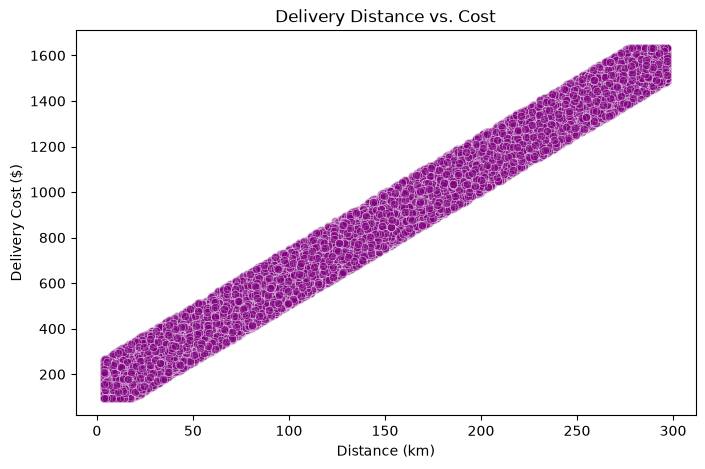

In [78]:
#Finding correltation between distance and cost.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='distance_km', y='delivery_cost', alpha=0.5, color='purple')
plt.title('Delivery Distance vs. Cost')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Cost ($)')
plt.show()

## We can see a positive correlation between distance travelled for a delivery and the delivery cost.

## Which means as the distance of delivery increases the cost of delivery will also incerease.

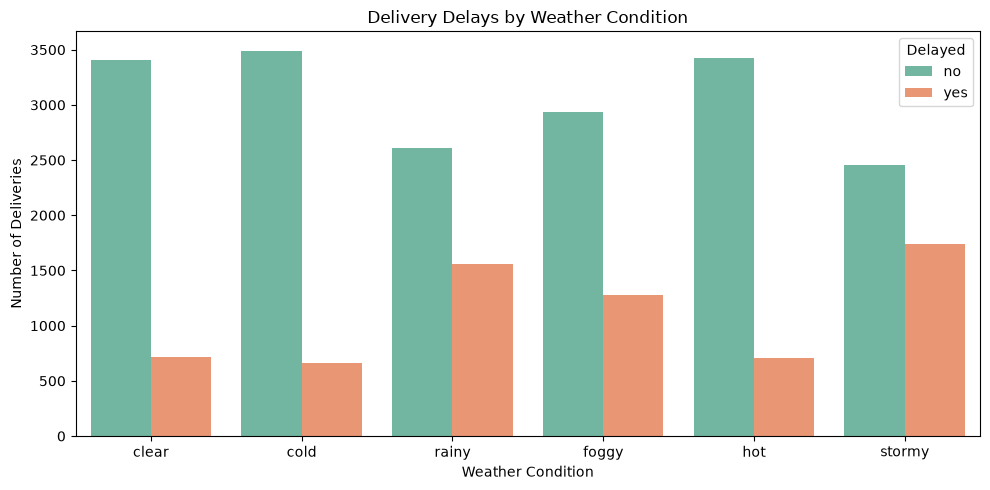

In [79]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='weather_condition', hue='delayed', palette='Set2')
plt.title('Delivery Delays by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Number of Deliveries')
plt.legend(title='Delayed', loc='upper right')
plt.tight_layout()
plt.show()

**Observation: Precipitation and Visibility Drive Delays**
The bar chart clearly demonstrates that adverse weather conditions—specifically stormy, rainy, and foggy weather—are the primary catalysts for delivery delays. While stable conditions like clear, cold, and hot weather maintain strong on-time performance with minimal delays (roughly 700 delayed shipments each), stormy weather causes a massive disruption, spiking to over 1,500 delayed deliveries. Rainy conditions follow closely behind as the second-highest driver of delays.

**Broader Business Implication & Strategy**
The logistics network is highly vulnerable to precipitation and low visibility. To mitigate this, the company should implement a weather-responsive dispatch strategy. When storms or heavy rain are forecasted, the system could automatically shift dispatch priority to enclosed, heavy-duty vehicles (like vans and trucks) rather than exposed two-wheelers. Additionally, customer service can use weather forecasts to send proactive SMS alerts about potential delays, managing customer expectations before a delivery deadline is actually missed.